## Spatial Model Error Mapping
- V2 is for season length and other statistics calculated from OutputStatsV2.py

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

In [2]:
# Load the CSV data
df = pd.read_csv('../outputV2_sitesV2_s01011010_gbc_v0005.csv')
df.head()

,site,latitude,longitude,avg_snow_days_snotel,avg_snow_days_model,avg_snow_days_model_all,avg_onset_doy_model_all,avg_meltout_doy_model_all,n_matched_snow_years,n_snow_years_model,avg_peak_doy_snotel,avg_peak_doy_model,avg_peak_doy_model_all,avg_peak_swe_snotel,avg_peak_swe_model,avg_peak_swe_model_all,n_matched_peak_years,n_peak_years_model
0,Forestdale Creek,38.682311,-119.960653,204.9,201.4,201.6,313.5,151.8,14,15,88.6,86.6,87.1,877.0,887.200012,904.7,14,15
1,Horse Meadow,38.836411,-119.888317,183.2,173.9,179.5,311.5,138.4,9,11,78.3,87.8,90.0,435.0,444.600006,534.4,9,11
2,Burnside Lake,38.719328,-119.895194,190.8,190.5,190.5,314.3,145.8,15,15,85.0,88.9,88.9,674.1,759.700012,759.7,15,15
3,Summit Meadow,38.397400,-119.536217,179.2,187.7,199.9,307.9,145.9,6,9,91.2,94.8,95.1,387.7,402.200012,520.1,6,9
4,Carson Pass,38.692667,-120.002128,206.5,199.2,199.2,312.1,148.0,12,13,90.7,88.6,88.9,816.2,765.099976,781.7,12,13


In [4]:
df[df.site == 'Pepper Creek']

,site,latitude,longitude,avg_snow_days_snotel,avg_snow_days_model,avg_snow_days_model_all,avg_onset_doy_model_all,avg_meltout_doy_model_all,n_matched_snow_years,n_snow_years_model,avg_peak_doy_snotel,avg_peak_doy_model,avg_peak_doy_model_all,avg_peak_swe_snotel,avg_peak_swe_model,avg_peak_swe_model_all,n_matched_peak_years,n_peak_years_model
624,Pepper Creek,46.1,-121.96,117.2,13.8,13.8,207.0,78.0,11,11,54.1,212.5,212.5,268.3,35.0,35.0,11,11


In [5]:
# Remove sites where snotel has less than 5 years
df = df[df['n_matched_snow_years'] >= 5]

### Snow Days
Compare model snow days to snotel

In [6]:
snow_days = df[['site','latitude','longitude','avg_snow_days_snotel','avg_snow_days_model']]

In [7]:
snow_days['model_snotel_ddays'] = snow_days['avg_snow_days_model'] - snow_days['avg_snow_days_snotel']

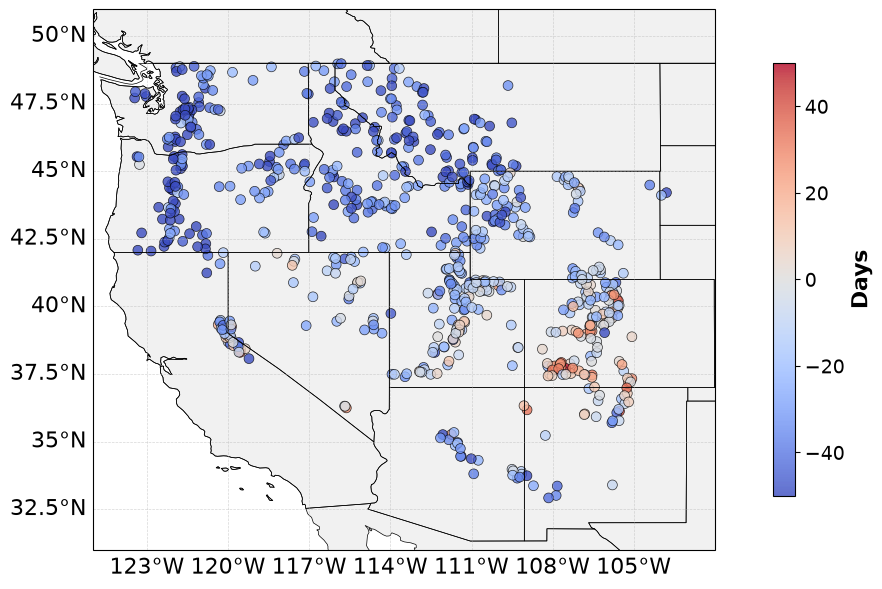

In [8]:
# Snow days map
fig = plt.figure(figsize=(12, 6))
ax = plt.subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax.set_extent([-125, -102, 31, 51], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.STATES, linewidth=0.5, edgecolor='black')
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.3)
scatter = ax.scatter(snow_days['longitude'], snow_days['latitude'],
                     c=snow_days['model_snotel_ddays'],
                     s=50,
                     alpha=0.8,
                     cmap='coolwarm',
                     vmin=-50,
                     vmax=50,
                     transform=ccrs.PlateCarree(),
                     edgecolors='black',
                     linewidth=0.5)
cbar = plt.colorbar(scatter, ax=ax, orientation='vertical', pad=0.05, shrink=0.8)
cbar.set_label('Days', fontsize=16, fontweight='bold')
cbar.ax.tick_params(labelsize=14)
gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5, linestyle='--')
gl.top_labels = False
gl.right_labels = False
gl.geo_labels = False
gl.xlabel_style = {'size': 16}
gl.ylabel_style = {'size': 16}
plt.tight_layout()
#fig.savefig('../images/ElevationMap.pdf', bbox_inches='tight')

#### Analysis
- 01011010_ghelaps_v0008: patterns looks like bias pattern, but in Arizona there are a cluster of sites with high bias but season length too short.
- 01011010_gbc_v0005: Looks exactly like the bias pattern.

### Peak SWE

Compare model peak SWE date to snotel, in day of water year (Oct 1 = day 1). `OutputStatsV2.py` computes `avg_peak_wydoy_*` this way (rather than calendar day-of-year) so that a peak occurring in Oct-Dec and one occurring in Jan-Jul are on the same continuous, averaging-safe scale — calendar DOY would otherwise wrap an early-season peak to a large value that isn't comparable to a late-season peak's small one.

In [ ]:
peak_doy = df[['site','latitude','longitude','avg_peak_wydoy_snotel','avg_peak_wydoy_model']]

In [ ]:
peak_doy['model_snotel_ddoy'] = peak_doy['avg_peak_wydoy_model'] - peak_doy['avg_peak_wydoy_snotel']

In [ ]:
# Peak SWE DOY map
fig = plt.figure(figsize=(12, 6))
ax = plt.subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax.set_extent([-125, -102, 31, 51], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.STATES, linewidth=0.5, edgecolor='black')
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.3)
scatter = ax.scatter(peak_doy['longitude'], peak_doy['latitude'],
                     c=peak_doy['model_snotel_ddoy'],
                     s=50,
                     alpha=0.8,
                     cmap='coolwarm',
                     vmin=-50,
                     vmax=50,
                     transform=ccrs.PlateCarree(),
                     edgecolors='black',
                     linewidth=0.5)
cbar = plt.colorbar(scatter, ax=ax, orientation='vertical', pad=0.05, shrink=0.8)
cbar.set_label('Days', fontsize=16, fontweight='bold')
cbar.ax.tick_params(labelsize=14)
gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5, linestyle='--')
gl.top_labels = False
gl.right_labels = False
gl.geo_labels = False
gl.xlabel_style = {'size': 16}
gl.ylabel_style = {'size': 16}
plt.tight_layout()
#fig.savefig('../images/ElevationMap.pdf', bbox_inches='tight')

#### Unusual sites: shorter model season but later model peak
Identify sites where the model season is much shorter than observed (`model_snotel_ddays` very negative) while the model peak SWE date is much later than observed (`model_snotel_ddoy` very positive) — an unexpected combination.

In [ ]:
# Combine the two diagnostics on site
unusual = snow_days[['site','latitude','longitude','model_snotel_ddays']].merge(
    peak_doy[['site','model_snotel_ddoy']], on='site'
)

# Score is only large when BOTH anomalies are present and severe:
# shorter model season (ddays << 0) and later model peak (ddoy >> 0).
# Using the min of the two "unusualness" directions means one large term
# can't inflate the score if the other condition isn't also met.
unusual['unusual_score'] = np.minimum(-unusual['model_snotel_ddays'], unusual['model_snotel_ddoy'])

top5 = unusual.sort_values('unusual_score', ascending=False).head(5)
top5[['site','latitude','longitude','model_snotel_ddays','model_snotel_ddoy','unusual_score']]